**TLDR**: Trains an L2-regularised logistic-regression classifier on the PCA components to estimate P(FAIL) for each image. Training is posed as finding the root of the gradient and solved two ways: Newton's method (the shooting-method update applied to the gradient, with LU solves; quadratic convergence) and gradient descent (explicit Euler on the gradient flow; linear convergence, subject to the explicit-Euler stability limit). Verified by central finite-difference derivative checks, agreement with scikit-learn, convergence-rate tests and a stability test. Implemented in `src/porkqc/logistic.py` and `src/porkqc/model.py`, on the `feature/logistic` branch.

## Method

For PCA scores $x_i$ and labels $y_i \in \{0,1\}$, the model predicts $p_i = \sigma(z_i)$ with $z_i = w^\top x_i + b$. Training minimises

$$f(\theta) = \frac{1}{n}\sum_{i=1}^{n}\left[\log\left(1+e^{z_i}\right) - y_i z_i\right] + \frac{\lambda}{2}\lVert w\rVert^2, \qquad \theta = [w, b].$$

$f$ is strictly convex, so its minimum is the unique root of the gradient, $\nabla f(\theta) = 0$, where, with $A = [X, \mathbf{1}]$,

$$\nabla f = \tfrac{1}{n}A^\top(p - y) + \lambda[w, 0], \qquad H = \nabla^2 f = \tfrac{1}{n}A^\top \operatorname{diag}\big(p(1-p)\big)A + \lambda\operatorname{diag}(1,\dots,1,0).$$

- **Newton's method** applies the shooting-method update $s \leftarrow s - F(s)/F'(s)$ to the system $\nabla f(\theta) = 0$: each iteration solves $H\,\Delta\theta = -\nabla f$ by LU factorisation. Convergence is quadratic near the root.
- **Gradient descent**, $\theta \leftarrow \theta - h\nabla f(\theta)$, is the explicit Euler method for $\dot\theta = -\nabla f(\theta)$. Near the minimum the error is multiplied by $(I - hH)$, so it is stable only if $h < 2/\lambda_{\max}(H)$, the explicit-Euler limit for $y' = -\lambda y$. Convergence is linear.
- Both stop when the residual $\lVert\nabla f\rVert_\infty \le \text{tol}$.

##Set Up

In [3]:
from google.colab import drive, userdata
drive.mount('/content/drive')

REPO_DIR = "/content/drive/MyDrive/MMA3001 Project/Pork-Tray-Inspection"
ZIP_PATH = "/content/drive/MyDrive/MMA3001/Pork Rasher Error-Packaging-.v4i.coco.zip"
%cd "{REPO_DIR}"

token = userdata.get("GITHUB_TOKEN")
PUSH_URL = f"https://{token}@github.com/chrixxv1/Pork-Tray-Inspection.git"

!mkdir -p /content/data
!unzip -oq "{ZIP_PATH}" -d /content/data
DATA_DIR = "/content/data"
CACHE_DIR = f"{REPO_DIR}/results/cache"

!pip install -q -e .
import sys
sys.path.insert(0, f"{REPO_DIR}/src")
!git branch

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/MMA3001 Project/Pork-Tray-Inspection
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for porkqc (pyproject.toml) ... done
  feature/data-loader
  feature/features
  feature/pca
* main


##Branching

In [4]:
!git switch main
!git pull {PUSH_URL} main
!git switch -c feature/logistic

M	notebooks/0_setup.ipynb
M	notebooks/1_exploring_data.ipynb
M	notebooks/3_features.ipynb
M	notebooks/4_pca.ipynb
Already on 'main'
Your branch is ahead of 'origin/main' by 16 commits.
  (use "git push" to publish your local commits)
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 937 bytes | 3.00 KiB/s, done.
From https://github.com/chrixxv1/Pork-Tray-Inspection
 * branch            main       -> FETCH_HEAD
Updating 3d53068..c685541
Fast-forward
 AI_USE_LOG.md | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
Switched to a new branch 'feature/logistic'


##Add SciPy as Dependency
Newton’s method uses SciPy’s LU factorisation.

In [5]:
%%writefile pyproject.toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "porkqc"
version = "0.1.0"
description = "Tray-level pass/fail inspection of packaged pork rashers"
requires-python = ">=3.10"
dependencies = ["numpy", "scipy", "pillow", "scikit-image", "scikit-learn"]

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]

Overwriting pyproject.toml


##Logistic Regression Module

In [6]:
%%writefile src/porkqc/logistic.py
"""L2-regularised logistic regression trained with Newton's method or gradient descent.

The model predicts ``P(FAIL | x) = sigmoid(w . x + b)``. Training minimises

    f(theta) = (1/n) sum_i [ log(1 + exp(z_i)) - y_i z_i ] + (lambda/2) ||w||^2,
    z_i = w . x_i + b,   theta = [w, b],

the mean negative log-likelihood plus a ridge penalty (the intercept ``b`` is
not penalised). ``f`` is convex, and strictly convex for ``lambda > 0``, so its
minimiser is the unique root of the gradient, ``grad f(theta) = 0``.

With ``p = sigmoid(z)`` and the augmented matrix ``A = [X, 1]``:

    gradient  g(theta) = A^T (p - y) / n + lambda [w, 0]
    Hessian   H(theta) = A^T diag(p (1 - p)) A / n + lambda diag(1, ..., 1, 0)

Solvers:

* ``"newton"`` - Newton's method for the root-finding problem ``g(theta) = 0``.
  It is the multivariate form of the scalar update ``s <- s - F(s) / F'(s)``
  used in the shooting method: here ``F`` is the gradient and ``F'`` is the
  Hessian, so each iteration solves the linear system ``H dtheta = -g`` by LU
  factorisation (``scipy.linalg.lu_factor`` / ``lu_solve``). Near the root the
  convergence is quadratic. As a safeguard against overshooting far from the
  root, a step that increases ``f`` is halved until it does not.
* ``"gd"`` - gradient descent, ``theta <- theta - h g(theta)``. This is the
  explicit (forward) Euler method applied to the gradient-flow ODE
  ``d theta / dt = -g(theta)``. Near the minimum ``g`` is approximately
  ``H (theta - theta*)``, so the error is multiplied by ``(I - h H)`` each step
  and the iteration is stable only if ``|1 - h lambda_i| < 1`` for every
  eigenvalue ``lambda_i`` of ``H``, i.e. ``0 < h < 2 / lambda_max`` - the same
  limit as explicit Euler for ``y' = -lambda y``. Convergence is linear, at a
  rate set by the condition number of ``H``. It is the baseline solver.

Both solvers stop when the residual ``||g(theta)||_inf <= tol``, the same kind
of stopping rule as the shooting method (``|F(s)| < tol``) and the relaxation
methods (``||A T - b||_inf``). For a strongly convex ``f`` this residual also
bounds the parameter error: ``||theta - theta*||_2 <= ||g||_2 / mu``, where
``mu`` is the smallest eigenvalue of ``H``.
"""

from __future__ import annotations

import time
from dataclasses import dataclass, field

import numpy as np
from scipy.linalg import lu_factor, lu_solve


def sigmoid(z: np.ndarray) -> np.ndarray:
    """Numerically stable logistic function.

    The naive ``1 / (1 + exp(-z))`` overflows ``exp`` for large negative ``z``
    (float64 overflows above about 1.8e308, i.e. ``z < -709``). Evaluating
    separately on each sign keeps every ``exp`` argument non-positive, so it
    can only underflow harmlessly to 0.

    Args:
        z: Array of logits.

    Returns:
        Array of the same shape with values in [0, 1].
    """
    z = np.asarray(z, dtype=np.float64)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def log_loss(y: np.ndarray, z: np.ndarray) -> float:
    """Mean negative log-likelihood computed from logits.

    Uses ``log(1 + exp(z)) = logaddexp(0, z)``, which never overflows, instead
    of ``log(sigmoid(z))``, which returns ``-inf`` once ``sigmoid`` rounds to 0.

    Args:
        y: Labels in {0, 1}.
        z: Logits, same shape as ``y``.

    Returns:
        The mean loss (a non-negative float).
    """
    return float(np.mean(np.logaddexp(0.0, z) - y * z))


@dataclass
class FitHistory:
    """Per-iteration record of an optimisation run.

    Attributes:
        loss: Objective value after each iteration (index 0 is the start).
        grad_norm: Residual ``||g||_inf`` after each iteration.
        time_s: Wall-clock time since the start of ``fit`` at each iteration.
        converged: Whether ``||g||_inf <= tol`` was reached within ``max_iter``.
    """

    loss: list[float] = field(default_factory=list)
    grad_norm: list[float] = field(default_factory=list)
    time_s: list[float] = field(default_factory=list)
    converged: bool = False


class LogisticRegression:
    """Binary L2-regularised logistic regression.

    Args:
        l2: Ridge penalty ``lambda`` (must be positive).
        solver: ``"newton"`` or ``"gd"``.
        tol: Stopping tolerance on the residual ``||grad f||_inf``.
        max_iter: Maximum number of iterations.
        step: Gradient-descent step size ``h``. If None, ``h = 1 / lambda_max``
            of the Hessian at the starting point, half the stability limit.
            Ignored by Newton's method.

    Attributes:
        coef_: Weights ``w``, shape ``(n_features,)``.
        intercept_: Bias ``b``.
        history_: :class:`FitHistory` of the last call to :meth:`fit`.
        hessian_cond_: Condition number ``sigma_max / sigma_min`` of the
            Hessian at the solution (Newton only).
        stability_limit_: ``2 / lambda_max`` of the starting Hessian, the
            largest stable gradient-descent step (gradient descent only).
        step_: Step size actually used (gradient descent only).
    """

    def __init__(self, l2: float = 1e-3, solver: str = "newton", tol: float = 1e-8,
                 max_iter: int = 100, step: float | None = None) -> None:
        if l2 <= 0:
            raise ValueError("l2 must be positive so the problem is strictly convex")
        if solver not in ("newton", "gd"):
            raise ValueError("solver must be 'newton' or 'gd'")
        if step is not None and step <= 0:
            raise ValueError("step must be positive")
        self.l2 = l2
        self.solver = solver
        self.tol = tol
        self.max_iter = max_iter
        self.step = step

    # ------------------------------------------------------------------ helpers
    def _objective(self, A: np.ndarray, y: np.ndarray, theta: np.ndarray) -> float:
        w = theta[:-1]
        return log_loss(y, A @ theta) + 0.5 * self.l2 * float(w @ w)

    def _gradient(self, A: np.ndarray, y: np.ndarray, theta: np.ndarray) -> np.ndarray:
        n = A.shape[0]
        g = A.T @ (sigmoid(A @ theta) - y) / n
        g[:-1] += self.l2 * theta[:-1]
        return g

    def _hessian(self, A: np.ndarray, theta: np.ndarray) -> np.ndarray:
        n = A.shape[0]
        p = sigmoid(A @ theta)
        s = p * (1.0 - p)
        H = (A * s[:, None]).T @ A / n  # A^T diag(s) A without forming diag(s)
        H[np.diag_indices(A.shape[1] - 1)] += self.l2
        return H

    # --------------------------------------------------------------------- API
    def fit(self, X: np.ndarray, y: np.ndarray) -> "LogisticRegression":
        """Fit the model.

        Args:
            X: Features, shape ``(n_samples, n_features)``.
            y: Labels in {0, 1}, shape ``(n_samples,)``.

        Returns:
            The fitted instance.

        Raises:
            ValueError: If shapes disagree, labels are not 0/1, or inputs
                contain non-finite values.
        """
        X, y = _check_xy(X, y)
        A = np.hstack([X, np.ones((X.shape[0], 1))])
        theta = np.zeros(A.shape[1])
        self.history_ = FitHistory()
        t0 = time.perf_counter()

        def record(theta: np.ndarray, g: np.ndarray) -> None:
            self.history_.loss.append(self._objective(A, y, theta))
            self.history_.grad_norm.append(float(np.abs(g).max()))
            self.history_.time_s.append(time.perf_counter() - t0)

        g = self._gradient(A, y, theta)
        record(theta, g)
        if self.solver == "newton":
            theta = self._fit_newton(A, y, theta, g, record)
        else:
            theta = self._fit_gd(A, y, theta, g, record)

        self.coef_ = theta[:-1]
        self.intercept_ = float(theta[-1])
        return self

    def _fit_newton(self, A, y, theta, g, record):
        for _ in range(self.max_iter):
            if np.abs(g).max() <= self.tol:
                self.history_.converged = True
                break
            # Newton update: solve H dtheta = -g by LU factorisation.
            H = self._hessian(A, theta)
            dtheta = lu_solve(lu_factor(H), -g)
            # Safeguard: halve the step while it would increase f.
            f0, t = self._objective(A, y, theta), 1.0
            while self._objective(A, y, theta + t * dtheta) > f0 and t > 1e-10:
                t *= 0.5
            theta = theta + t * dtheta
            g = self._gradient(A, y, theta)
            record(theta, g)
        # Condition number sigma_max / sigma_min (computed via the SVD).
        self.hessian_cond_ = float(np.linalg.cond(self._hessian(A, theta)))
        return theta

    def _fit_gd(self, A, y, theta, g, record):
        # At theta = 0 every p = 1/2, where p(1 - p) takes its maximum of 1/4,
        # so the starting Hessian has the largest curvature anywhere and its
        # top eigenvalue gives a stability limit that holds for every theta.
        lam_max = float(np.linalg.eigvalsh(self._hessian(A, theta))[-1])
        self.stability_limit_ = 2.0 / lam_max
        self.step_ = self.step if self.step is not None else 1.0 / lam_max
        for _ in range(self.max_iter):
            if np.abs(g).max() <= self.tol:
                self.history_.converged = True
                break
            theta = theta - self.step_ * g
            g = self._gradient(A, y, theta)
            record(theta, g)
            if not np.isfinite(self.history_.loss[-1]):
                break  # diverged (unstable step size)
        return theta

    def decision_function(self, X: np.ndarray) -> np.ndarray:
        """Return the logits ``w . x + b``, shape ``(n_samples,)``."""
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2 or X.shape[1] != self.coef_.shape[0]:
            raise ValueError(f"Expected shape (n, {self.coef_.shape[0]}), got {X.shape}")
        return X @ self.coef_ + self.intercept_

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Return ``P(FAIL | x)`` for each row of ``X``, shape ``(n_samples,)``."""
        return sigmoid(self.decision_function(X))


def _check_xy(X: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Validate and convert training inputs."""
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    if X.ndim != 2:
        raise ValueError("X must be 2-D")
    if y.shape != (X.shape[0],):
        raise ValueError(f"y must have shape ({X.shape[0]},), got {y.shape}")
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValueError("Inputs contain NaN or infinite values")
    if not np.isin(y, (0.0, 1.0)).all():
        raise ValueError("y must contain only 0 and 1")
    return X, y

Writing src/porkqc/logistic.py


##Pipeline Module

In [7]:
%%writefile src/porkqc/model.py
"""End-to-end classifier: PCA (with whitening), then logistic regression."""

from __future__ import annotations

import numpy as np

from .logistic import LogisticRegression
from .pca import PCA


class TrayClassifier:
    """PCA + logistic-regression pipeline for tray-level pass/fail.

    Args:
        n_components: Number of principal components kept.
        l2: Ridge penalty of the logistic regression.
        solver: Logistic-regression solver, ``"newton"`` or ``"gd"``.
        pca_solver: PCA solver, ``"full"`` or ``"randomized"``.
        max_iter: Maximum solver iterations.

    Attributes:
        pca_: Fitted :class:`~porkqc.pca.PCA`.
        clf_: Fitted :class:`~porkqc.logistic.LogisticRegression`.
    """

    def __init__(self, n_components: int = 100, l2: float = 1e-2, solver: str = "newton",
                 pca_solver: str = "full", max_iter: int = 100) -> None:
        self.n_components = n_components
        self.l2 = l2
        self.solver = solver
        self.pca_solver = pca_solver
        self.max_iter = max_iter

    def fit(self, X: np.ndarray, y: np.ndarray) -> "TrayClassifier":
        """Fit PCA on ``X`` and the classifier on the whitened PCA scores.

        Args:
            X: Raw features, shape ``(n_samples, n_features)``.
            y: Labels in {0, 1}.

        Returns:
            The fitted instance.
        """
        self.pca_ = PCA(self.n_components, whiten=True, solver=self.pca_solver).fit(X)
        self.clf_ = LogisticRegression(self.l2, self.solver, max_iter=self.max_iter)
        self.clf_.fit(self.pca_.transform(X), y)
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Return ``P(FAIL)`` for each row of ``X``."""
        return self.clf_.predict_proba(self.pca_.transform(X))

Writing src/porkqc/model.py


##Training on Real Data & Comparing Solvers
This uses HOG features compressed to 50 whitened PCA components, with λ = 10⁻⁴. Phase 6 tunes these settings properly. The PCA fit takes up to about a minute.

In [8]:
import numpy as np
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.metrics import roc_auc_score
from porkqc.data import load_dataset
from porkqc.features import extract
from porkqc.pca import PCA
from porkqc.logistic import LogisticRegression

ds = load_dataset(DATA_DIR)
X_train, y_train = extract(ds["train"], "hog", cache_dir=CACHE_DIR)
X_valid, y_valid = extract(ds["valid"], "hog", cache_dir=CACHE_DIR)
pca = PCA(400, whiten=True).fit(X_train)
Z_train, Z_valid = pca.transform(X_train), pca.transform(X_valid)

k, l2 = 50, 1e-4
newton = LogisticRegression(l2=l2, solver="newton", tol=1e-10).fit(Z_train[:, :k], y_train)
gd = LogisticRegression(l2=l2, solver="gd", tol=1e-8, max_iter=20_000).fit(Z_train[:, :k], y_train)
# scikit-learn's C relates to our lambda by C = 1 / (lambda * n)
sk = SkLR(C=1 / (l2 * len(y_train)), tol=1e-12, max_iter=10_000).fit(Z_train[:, :k], y_train)

print(f"Newton: {len(newton.history_.loss) - 1} iterations, Hessian condition number {newton.hessian_cond_:.1f}")
print("Newton residuals:", [f"{r:.1e}" for r in newton.history_.grad_norm])
print(f"Gradient descent: {len(gd.history_.loss) - 1} iterations")
print(f"max |w_newton - w_gd|      = {np.abs(newton.coef_ - gd.coef_).max():.1e}")
print(f"max |w_newton - w_sklearn| = {np.abs(newton.coef_ - sk.coef_.ravel()).max():.1e}")
print(f"Validation AUC: {roc_auc_score(y_valid, newton.predict_proba(Z_valid[:, :k])):.3f}")

Newton: 6 iterations, Hessian condition number 7.5
Newton residuals: ['3.0e-01', '4.8e-02', '1.1e-02', '1.9e-03', '9.6e-05', '2.8e-07', '2.3e-12']
Gradient descent: 104 iterations
max |w_newton - w_gd|      = 2.8e-07
max |w_newton - w_sklearn| = 3.1e-08
Validation AUC: 0.784


##Convergence Plot: Newton Vs. Gradient Descent

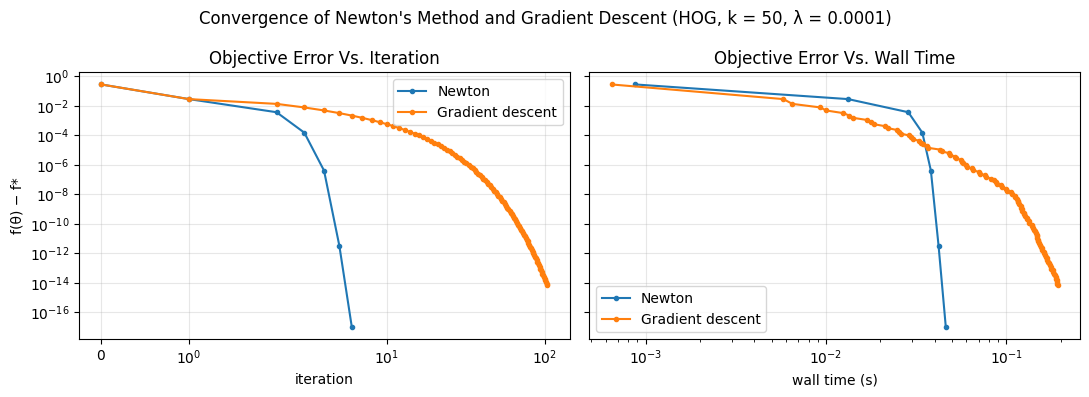

In [11]:
import matplotlib.pyplot as plt

f_star = min(newton.history_.loss)   # Newton reaches the optimum to round-off level
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for model, name in ((newton, "Newton"), (gd, "Gradient descent")):
    err = np.maximum(np.array(model.history_.loss) - f_star, 1e-17)
    axes[0].semilogy(err, ".-", label=name)
    axes[1].semilogy(model.history_.time_s, err, ".-", label=name)
axes[0].set(xlabel="iteration", ylabel="f(θ) − f*", xscale="symlog",
            title="Objective Error Vs. Iteration")
axes[1].set(xlabel="wall time (s)", xscale="log",
            title="Objective Error Vs. Wall Time")
for a in axes:
    a.grid(alpha=0.3)
    a.legend()
fig.suptitle(f"Convergence of Newton's Method and Gradient Descent (HOG, k = {k}, λ = {l2:g})")
plt.tight_layout()
plt.show()

##Gradient Descent as Explicit Euler: Stability Limit

Stability limit 2/λmax = 8.00, default step h = 1/λmax = 4.00


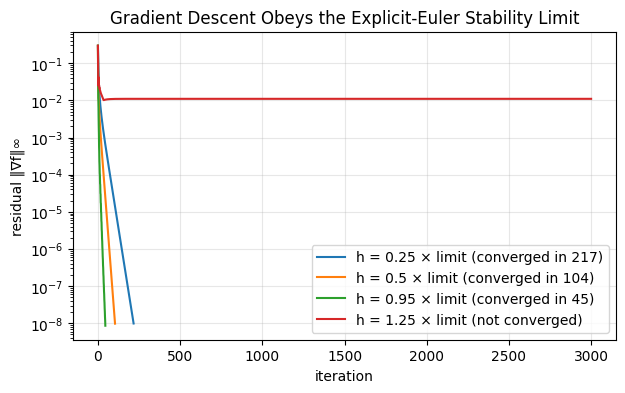

In [13]:
limit = gd.stability_limit_
print(f"Stability limit 2/λmax = {limit:.2f}, default step h = 1/λmax = {gd.step_:.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
for frac in (0.25, 0.5, 0.95, 1.25):
    m = LogisticRegression(l2=l2, solver="gd", tol=1e-8, max_iter=3000,
                           step=frac * limit).fit(Z_train[:, :k], y_train)
    status = f"converged in {len(m.history_.loss) - 1}" if m.history_.converged else "not converged"
    ax.semilogy(m.history_.grad_norm, label=f"h = {frac} × limit ({status})")
ax.set(xlabel="iteration", ylabel="residual ‖∇f‖∞",
       title="Gradient Descent Obeys the Explicit-Euler Stability Limit")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

##How Conditioning Affects Solvers

In [14]:
print(" k | Newton iters | GD iters | Hessian cond | valid AUC")
for kk in (10, 50, 200, 400):
    n_ = LogisticRegression(l2=l2, tol=1e-10).fit(Z_train[:, :kk], y_train)
    g_ = LogisticRegression(l2=l2, solver="gd", tol=1e-6, max_iter=20_000).fit(Z_train[:, :kk], y_train)
    auc = roc_auc_score(y_valid, n_.predict_proba(Z_valid[:, :kk]))
    print(f"{kk:3d} | {len(n_.history_.loss) - 1:12d} | {len(g_.history_.loss) - 1:8d} | {n_.hessian_cond_:12.1f} | {auc:.3f}")

 k | Newton iters | GD iters | Hessian cond | valid AUC
 10 |            5 |       27 |          2.6 | 0.651
 50 |            6 |       70 |          7.5 | 0.784
200 |            7 |      237 |         21.4 | 0.702
400 |            9 |     1906 |        166.4 | 0.638


##Add Test Fixture

In [15]:
%%writefile -a tests/conftest.py


@pytest.fixture
def logistic_data():
    """Non-separable two-class data with known structure: n=400, d=5."""
    import numpy as np

    rng = np.random.default_rng(1)
    X = rng.standard_normal((400, 5))
    w_true = np.array([2.0, -1.0, 0.5, 0.0, 0.0])
    y = (rng.random(400) < 1 / (1 + np.exp(-(X @ w_true + 0.3)))).astype(float)
    return X, y

Appending to tests/conftest.py


##Tests for Logistic Regression

In [18]:
%%writefile tests/test_logistic.py
"""Verification of the logistic-regression solvers.

Four kinds of evidence:
1. the gradient and Hessian are checked against central finite differences;
2. the Newton solution is checked against an established implementation
   (scikit-learn) on the same objective;
3. convergence behaviour matches theory (quadratic for Newton, linear for
   gradient descent, both reaching the same solution);
4. gradient descent obeys the explicit-Euler stability limit h < 2 / lambda_max.
"""

import warnings

import numpy as np
import pytest
from sklearn.linear_model import LogisticRegression as SkLR

from porkqc.logistic import LogisticRegression, log_loss, sigmoid


def _augmented(X):
    return np.hstack([X, np.ones((X.shape[0], 1))])


# ---------------------------------------------------------------- stability of the formulas
def test_sigmoid_is_stable_for_extreme_logits():
    z = np.array([-1000.0, -50.0, 0.0, 50.0, 1000.0])
    with warnings.catch_warnings():
        warnings.simplefilter("error")  # any overflow warning fails the test
        p = sigmoid(z)
    assert np.all(np.isfinite(p))
    assert p[0] == 0.0 and p[-1] == 1.0 and p[2] == 0.5


def test_sigmoid_matches_naive_formula_in_safe_range():
    z = np.linspace(-20, 20, 101)
    np.testing.assert_allclose(sigmoid(z), 1 / (1 + np.exp(-z)), rtol=1e-12)


def test_log_loss_is_finite_for_confident_wrong_predictions():
    # Naive log(sigmoid(z)) would give -inf here.
    assert np.isclose(log_loss(np.array([1.0]), np.array([-800.0])), 800.0)


# ---------------------------------------------------------------- derivatives
# Central differences have truncation error O(h^2) and round-off error
# O(u / h), with u ~ 1.1e-16 for float64, so the total error is smallest near
# h ~ u^(1/3) ~ 5e-6. h = 1e-6 is close to that optimum.
H_FD = 1e-6


def test_gradient_matches_central_finite_differences(logistic_data):
    X, y = logistic_data
    m = LogisticRegression(l2=0.1)
    A = _augmented(X)
    theta = np.random.default_rng(2).standard_normal(A.shape[1]) * 0.5
    fd = np.array([(m._objective(A, y, theta + H_FD * e) - m._objective(A, y, theta - H_FD * e))
                   / (2 * H_FD) for e in np.eye(len(theta))])
    np.testing.assert_allclose(m._gradient(A, y, theta), fd, rtol=1e-6, atol=1e-9)


def test_hessian_matches_central_finite_differences_of_gradient(logistic_data):
    X, y = logistic_data
    m = LogisticRegression(l2=0.1)
    A = _augmented(X)
    theta = np.random.default_rng(3).standard_normal(A.shape[1]) * 0.5
    fd = np.stack([(m._gradient(A, y, theta + H_FD * e) - m._gradient(A, y, theta - H_FD * e))
                   / (2 * H_FD) for e in np.eye(len(theta))])
    np.testing.assert_allclose(m._hessian(A, theta), fd, rtol=1e-5, atol=1e-8)


# ---------------------------------------------------------------- Newton's method
def test_newton_matches_scikit_learn(logistic_data):
    X, y = logistic_data
    C = 1.0
    # sklearn minimises C*sum(loss) + ||w||^2/2, i.e. our objective with l2 = 1/(C n).
    ours = LogisticRegression(l2=1 / (C * len(y)), tol=1e-12).fit(X, y)
    ref = SkLR(C=C, tol=1e-12, max_iter=10_000).fit(X, y)
    np.testing.assert_allclose(ours.coef_, ref.coef_.ravel(), atol=1e-5)
    assert abs(ours.intercept_ - ref.intercept_[0]) < 1e-5


def test_newton_converges_in_few_iterations_and_monotonically(logistic_data):
    X, y = logistic_data
    m = LogisticRegression(l2=1e-2, tol=1e-10).fit(X, y)
    loss = np.array(m.history_.loss)
    assert m.history_.converged
    assert len(loss) <= 12  # quadratic convergence: a handful of steps
    assert np.all(np.diff(loss) <= 1e-15)  # the step-halving safeguard prevents increases


def test_newton_residual_decreases_quadratically(logistic_data):
    X, y = logistic_data
    m = LogisticRegression(l2=1e-2, tol=1e-14).fit(X, y)
    g = np.array(m.history_.grad_norm)
    g = g[g > 1e-13]  # ignore iterations already at round-off level
    # Quadratic convergence: r_{k+1} ~ C r_k^2, so log(r_{k+1}) / log(r_k) -> 2.
    ratios = np.log(g[2:]) / np.log(g[1:-1])
    assert ratios[-1] > 1.5


# ---------------------------------------------------------------- gradient descent
def test_gradient_descent_reaches_newton_solution(logistic_data):
    X, y = logistic_data
    newton = LogisticRegression(l2=1e-1, tol=1e-14).fit(X, y)
    gd = LogisticRegression(l2=1e-1, solver="gd", tol=1e-9, max_iter=20_000).fit(X, y)
    assert gd.history_.converged
    assert np.all(np.diff(gd.history_.loss) <= 1e-15)
    # ||theta - theta*|| <= ||g|| / mu with mu >= l2 = 0.1, so a 1e-9 residual
    # pins the parameters to well within 1e-6.
    np.testing.assert_allclose(gd.coef_, newton.coef_, atol=1e-6)
    assert len(gd.history_.loss) > 3 * len(newton.history_.loss)


def test_gradient_descent_obeys_explicit_euler_stability_limit(logistic_data):
    X, y = logistic_data
    # Just below the stability limit of the starting Hessian: converges.
    limit = LogisticRegression(l2=0.1, solver="gd", max_iter=0).fit(X, y).stability_limit_
    stable = LogisticRegression(l2=0.1, solver="gd", tol=1e-8, max_iter=5000,
                                step=0.95 * limit).fit(X, y)
    assert stable.history_.converged

    # Just above the limit at the solution, 2 / lambda_max(H*): the error is
    # amplified by |1 - h lambda_max| > 1 near the minimum, so it never converges.
    newton = LogisticRegression(l2=0.1, tol=1e-14).fit(X, y)
    A = _augmented(X)
    theta_star = np.r_[newton.coef_, newton.intercept_]
    lam_max_star = np.linalg.eigvalsh(newton._hessian(A, theta_star))[-1]
    unstable = LogisticRegression(l2=0.1, solver="gd", tol=1e-8, max_iter=5000,
                                  step=1.1 * 2 / lam_max_star).fit(X, y)
    assert not unstable.history_.converged
    assert np.any(np.diff(unstable.history_.loss) > 0)  # loss is not monotone


# ---------------------------------------------------------------- robustness and inputs
def test_separable_data_gives_finite_solution():
    # Without regularisation the solution would diverge to infinity.
    X = np.array([[-2.0], [-1.0], [1.0], [2.0]])
    y = np.array([0.0, 0.0, 1.0, 1.0])
    m = LogisticRegression(l2=1e-3).fit(X, y)
    assert np.isfinite(m.coef_).all() and m.history_.converged


@pytest.mark.parametrize("X, y, msg", [
    (np.zeros(5), np.zeros(5), "2-D"),
    (np.zeros((5, 2)), np.zeros(4), "shape"),
    (np.zeros((3, 2)), np.array([0.0, 1.0, 2.0]), "only 0 and 1"),
    (np.full((2, 2), np.nan), np.zeros(2), "NaN"),
])
def test_invalid_inputs_are_rejected(X, y, msg):
    with pytest.raises(ValueError, match=msg):
        LogisticRegression().fit(X, y)


def test_invalid_settings_are_rejected():
    with pytest.raises(ValueError):
        LogisticRegression(l2=0)
    with pytest.raises(ValueError):
        LogisticRegression(solver="adam")
    with pytest.raises(ValueError):
        LogisticRegression(solver="gd", step=-1.0)

Overwriting tests/test_logistic.py


##Tests for Pipeline

In [19]:
%%writefile tests/test_model.py
"""Tests of the PCA + logistic-regression pipeline."""

import numpy as np
from sklearn.metrics import roc_auc_score

from porkqc.model import TrayClassifier


def _signal_data(signal_scale):
    """300 samples, 50 features; the label depends only on feature 0."""
    rng = np.random.default_rng(0)
    X = rng.standard_normal((300, 50))
    X[:, 0] *= signal_scale
    y = (X[:, 0] + 0.3 * signal_scale * rng.standard_normal(300) > 0).astype(float)
    return X, y


def test_pipeline_learns_a_high_variance_signal():
    X, y = _signal_data(signal_scale=5.0)
    clf = TrayClassifier(n_components=10, l2=1e-3).fit(X[:200], y[:200])
    assert roc_auc_score(y[200:], clf.predict_proba(X[200:])) > 0.9


def test_pca_can_discard_a_low_variance_signal():
    """Documents a known limitation: PCA is unsupervised.

    When the label depends on a direction with no more variance than the
    noise, truncating to a few components can discard it, and the classifier
    falls to near-chance. A supervised projection or more components would be
    needed in that case.
    """
    X, y = _signal_data(signal_scale=1.0)
    truncated = TrayClassifier(n_components=10, l2=1e-3).fit(X[:200], y[:200])
    complete = TrayClassifier(n_components=50, l2=1e-3).fit(X[:200], y[:200])
    assert roc_auc_score(y[200:], complete.predict_proba(X[200:])) > 0.9
    assert roc_auc_score(y[200:], truncated.predict_proba(X[200:])) < 0.75


def test_newton_and_gd_pipelines_agree():
    rng = np.random.default_rng(1)
    X = rng.standard_normal((200, 30))
    y = (rng.random(200) < 0.5).astype(float)
    a = TrayClassifier(5, l2=1e-1, solver="newton").fit(X, y).predict_proba(X)
    b = TrayClassifier(5, l2=1e-1, solver="gd", max_iter=5000).fit(X, y).predict_proba(X)
    np.testing.assert_allclose(a, b, atol=1e-4)

Writing tests/test_model.py


##Run Tests



In [20]:
!pytest -q

............................................                             [100%]
44 passed in 3.25s


##AI Usage Log

In [21]:
%%writefile -a AI_USE_LOG.md
| 2026-10-26 | Claude | Wrote the code: src/porkqc/logistic.py (Newton's method in the shooting-method form with LU solves and a residual stopping criterion; gradient descent framed as explicit Euler with its stability limit), src/porkqc/model.py, the solver, stability and conditioning analyses, and 19 tests | Checked the methods against my Week 9, Week 11 and Workshop 2 notebooks; confirmed Newton matches scikit-learn to ~3e-8 on the real data; ran all tests (44 passed); asked Claude to explain parts I did not understand |

Appending to AI_USE_LOG.md


## Documentation

In [24]:
%%writefile docs/5_logistic_regression.md
# Phase 5: Logistic regression with Newton's method and gradient descent

Notebook: `notebooks/5_logistic.ipynb`. Code: `src/porkqc/logistic.py`, `src/porkqc/model.py`.

## Method

Logistic regression estimates P(FAIL) from the PCA scores of each image. Training
minimises the mean negative log-likelihood plus an L2 penalty, which is posed as
finding the root of the gradient, ∇f(θ) = 0. Two solvers are compared:

- **Newton's method**: the shooting-method update s ← s − F/F′ applied to ∇f = 0.
  Each iteration solves H Δθ = −∇f by LU factorisation.
- **Gradient descent**: θ ← θ − h∇f, which is explicit Euler applied to
  dθ/dt = −∇f, so it is stable only for h < 2/λ_max(H).

Both stop when the residual ‖∇f‖∞ ≤ tol.

## Results (HOG features, k = 50 PCA components, λ = 1e-4)

| Measure | Newton | Gradient descent |
|---|---|---|
| Iterations to converge | 6 (tol 1e-10) | 104 (tol 1e-8) |
| Convergence rate | Quadratic | Linear |
| Agreement with scikit-learn (max coefficient difference) | 3e-8 | 3e-7 vs Newton |

Validation AUC: 0.784.

## Verification

- Gradient and Hessian match central finite differences (h = 1e-6, near the
  optimal step u^(1/3) for float64).
- Newton's solution matches scikit-learn to ~3e-8 on the real data.
- Newton's residual shows quadratic convergence; gradient descent reaches the
  same solution.
- The sigmoid and loss are evaluated in overflow-safe forms.
- 44 pytest tests pass.

## Stability of gradient descent

The stability limit is 2/λ_max ≈ 8.0 (λ_max ≈ 1/4 because the PCA scores are
whitened). Gradient descent converged in 217, 104 and 45 iterations at 0.25,
0.5 and 0.95 × the limit, and did not converge at 1.25 × the limit: the
residual stalled near 1e-2 as the iterates oscillated about the minimum. This
matches the explicit-Euler limit for y′ = −λy.

## Effect of the number of PCA components k

| k | Newton iterations | GD iterations | Hessian condition number | Validation AUC |
|---|---|---|---|---|
| 10 | 5 | 27 | 2.6 | 0.651 |
| 50 | 6 | 70 | 7.5 | 0.784 |
| 200 | 7 | 237 | 21.4 | 0.702 |
| 400 | 9 | 1906 | 166.4 | 0.638 |

Conditioning worsens as k grows, which slows gradient descent sharply while
Newton is barely affected. Validation AUC peaks near k = 50.

## Findings

- Newton's method is selected as the main solver: it needs far fewer iterations
  and is insensitive to conditioning.
- The residual cannot be reduced below about 1e-12, because round-off from
  summing over 3,349 training images sets a floor.
- Hyperparameters here are provisional; they are selected properly in Phase 6.

Writing docs/5_logistic_regression.md


In [25]:
!git add docs/5_logistic_regression.md
!git commit -m "Add Phase 5 results summary and convergence and stability figures"
!git push {PUSH_URL} HEAD

[main 6600bb4] Add Phase 5 results summary and convergence and stability figures
 1 file changed, 64 insertions(+)
 create mode 100644 docs/5_logistic_regression.md
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.73 KiB | 295.00 KiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/chrixxv1/Pork-Tray-Inspection.git
   b7d71f3..6600bb4  HEAD -> main


##Commit

In [22]:
!git add pyproject.toml src/porkqc/logistic.py src/porkqc/model.py tests/conftest.py tests/test_logistic.py tests/test_model.py notebooks/5_logistic.ipynb AI_USE_LOG.md
!git commit -m "Add logistic regression: Newton's method with LU solves and gradient descent as explicit Euler, verified against finite differences and scikit-learn"
!git push {PUSH_URL} feature/logistic

[feature/logistic 35df58c] Add logistic regression: Newton's method with LU solves and gradient descent as explicit Euler, verified against finite differences and scikit-learn
 8 files changed, 533 insertions(+), 1 deletion(-)
 create mode 100644 notebooks/5_logistic.ipynb
 create mode 100644 src/porkqc/logistic.py
 create mode 100644 src/porkqc/model.py
 create mode 100644 tests/test_logistic.py
 create mode 100644 tests/test_model.py
Enumerating objects: 22, done.
Counting objects: 100% (22/22), done.
Delta compression using up to 2 threads
Compressing objects: 100% (13/13), done.
Writing objects: 100% (14/14), 120.37 KiB | 4.63 MiB/s, done.
Total 14 (delta 6), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (6/6), completed with 6 local objects.
remote: 
remote: Create a pull request for 'feature/logistic' on GitHub by visiting:
remote:      https://github.com/chrixxv1/Pork-Tray-Inspection/pull/new/feature/logistic
remote: 
To https://github.com/chrixxv1/Pork-Tray-I

In [23]:
!git pull {PUSH_URL} main
!git branch -f main HEAD
!git switch main
!git log --oneline -3

remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (1/1), 941 bytes | 37.00 KiB/s, done.
From https://github.com/chrixxv1/Pork-Tray-Inspection
 * branch            main       -> FETCH_HEAD
Updating 35df58c..b7d71f3
Fast-forward
M	notebooks/0_setup.ipynb
M	notebooks/1_exploring_data.ipynb
M	notebooks/3_features.ipynb
M	notebooks/4_pca.ipynb
Switched to branch 'main'
Your branch is ahead of 'origin/main' by 19 commits.
  (use "git push" to publish your local commits)
b7d71f3 (HEAD -> main, feature/logistic) Merge pull request #4 from chrixxv1/feature/logistic
35df58c Add logistic regression: Newton's method with LU solves and gradient descent as explicit Euler, verified against finite differences and scikit-learn
c685541 Update AI_USE_LOG.md
